In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import statsmodels.api as sm

from sklearn.base import BaseEstimator, ClassifierMixin
from scipy.special import logsumexp
from scipy.stats import norm
import math

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    train_test_split, 
    StratifiedKFold, 
    GridSearchCV, 
    cross_validate
    )

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    roc_curve, 
    roc_auc_score
    )


## target

Bayesian Classification： 如何根據資料特性建立分類器，理解條件獨立性假設，以及評估分類效果。

Model Comparison： 如何使用 K-Fold Cross-Validation，公平比較 Bayesian Classifier 與 Decision Tree，最後選擇較合適的方法。

In [16]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yuanchunhong/university-football-injury-prediction-dataset")

print("Path to dataset files:", path)                   

Path to dataset files: C:\Users\USER\.cache\kagglehub\datasets\yuanchunhong\university-football-injury-prediction-dataset\versions\2


In [17]:
from pathlib import Path

csv_files = sorted(Path(path).rglob("*.csv"))

# Data Reading

In [18]:
df = pd.read_csv(csv_files[0])

print("資料形狀：", df.shape)
display(df.head(10))

資料形狀： (800, 19)


,Age,Height_cm,Weight_kg,Position,Training_Hours_Per_Week,Matches_Played_Past_Season,Previous_Injury_Count,Knee_Strength_Score,Hamstring_Flexibility,Reaction_Time_ms,Balance_Test_Score,Sprint_Speed_10m_s,Agility_Score,Sleep_Hours_Per_Night,Stress_Level_Score,Nutrition_Quality_Score,Warmup_Routine_Adherence,Injury_Next_Season,BMI
0,22,173,64,Midfielder,11.575308,36,1,77.460279,79.115738,284.487853,91.212476,5.874630,77.599705,8.238293,46.616415,81.472206,1,0,21.383942
1,18,170,67,Midfielder,12.275869,37,2,72.634442,82.541688,250.579249,87.294078,5.796269,94.418987,8.983737,49.368037,81.056677,1,0,23.183391
2,22,186,75,Forward,12.254896,12,2,77.064490,75.943631,269.119918,83.440688,5.731209,70.179176,7.229193,43.132808,64.877457,0,1,21.678807
3,20,172,62,Defender,9.006678,11,1,82.810232,73.878324,226.376412,87.591894,6.220212,83.473824,7.681029,51.528529,89.824744,1,0,20.957274
4,18,172,94,Midfielder,12.683668,10,2,76.772859,76.653043,229.021042,83.125161,5.385958,87.037256,6.728091,52.379718,71.569197,0,1,31.773932
5,23,189,89,Goalkeeper,10.262987,31,2,78.450720,80.927984,265.801623,81.106339,6.354870,86.418954,8.538027,39.929697,74.982476,1,0,24.915316
6,22,189,71,Midfielder,8.069288,5,4,63.045009,75.032030,269.099907,76.787369,6.458297,65.179995,7.339327,75.039112,65.790192,0,1,19.876263
7,23,184,75,Goalkeeper,6.407939,26,0,77.566677,76.947213,226.966431,93.317382,6.161460,79.260417,8.072895,25.783371,89.782578,0,0,22.152647
8,22,174,71,Midfielder,10.554931,23,0,78.877905,89.584501,240.745054,80.898575,6.199281,77.152290,7.661190,52.581600,78.587201,1,0,23.450918
9,23,185,76,Midfielder,11.899732,22,0,83.194761,82.244364,259.628161,89.077577,6.206694,90.396480,6.035505,55.049722,83.947949,1,0,22.205990


In [19]:
print("=== 欄位名稱 ===")
print(df.columns.tolist())

print("\n=== 資料型態 ===")
df.info()

print("\n=== 缺失值 ===")
display(df.isna().sum().to_frame("Missing_Count"))

=== 欄位名稱 ===
['Age', 'Height_cm', 'Weight_kg', 'Position', 'Training_Hours_Per_Week', 'Matches_Played_Past_Season', 'Previous_Injury_Count', 'Knee_Strength_Score', 'Hamstring_Flexibility', 'Reaction_Time_ms', 'Balance_Test_Score', 'Sprint_Speed_10m_s', 'Agility_Score', 'Sleep_Hours_Per_Night', 'Stress_Level_Score', 'Nutrition_Quality_Score', 'Warmup_Routine_Adherence', 'Injury_Next_Season', 'BMI']

=== 資料型態 ===
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         800 non-null    int64  
 1   Height_cm                   800 non-null    int64  
 2   Weight_kg                   800 non-null    int64  
 3   Position                    800 non-null    str    
 4   Training_Hours_Per_Week     800 non-null    float64
 5   Matches_Played_Past_Season  800 non-null    int64  
 6   Previous_Injury_Count       80

,Missing_Count
Age,0
Height_cm,0
Weight_kg,0
Position,0
Training_Hours_Per_Week,0
Matches_Played_Past_Season,0
Previous_Injury_Count,0
Knee_Strength_Score,0
Hamstring_Flexibility,0
Reaction_Time_ms,0


In [20]:
# 觀察y值資料分布
print("=== Injury Next Season ===")

display(
    pd.DataFrame({
        "Count": df["Injury_Next_Season"].value_counts().sort_index(),
        "Percentage": (
            df["Injury_Next_Season"]
            .value_counts(normalize=True)
            .sort_index() * 100
        ).round(2)
    })
)

=== Injury Next Season ===


,Count,Percentage
Injury_Next_Season,,
0,400,50.0
1,400,50.0


In [21]:
for col in ["Position", "Warmup_Routine_Adherence"]:
    print(f"\n=== {col} ===")
    display(df[col].value_counts(dropna=False))


=== Position ===


Position
Midfielder    213
Defender      204
Forward       197
Goalkeeper    186
Name: count, dtype: int64


=== Warmup_Routine_Adherence ===


Warmup_Routine_Adherence
1    478
0    322
Name: count, dtype: int64

In [22]:
# 檢查完全重複的資料
print("完全重複列數：", df.duplicated().sum())

# 不考慮 Y，檢查相同 X 是否重複
X_columns = df.columns.drop("Injury_Next_Season")

print(
    "相同特徵組合的重複列數：",
    df.duplicated(subset=X_columns).sum()
)

# 檢查類別和數值範圍
display(df.describe(include="all").T)

完全重複列數： 0
相同特徵組合的重複列數： 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,800.0,NaN,NaN,NaN,21.135,1.991037,18.0,19.0,21.0,23.0,24.0
Height_cm,800.0,NaN,NaN,NaN,177.4075,7.148974,154.0,173.0,177.0,182.0,200.0
Weight_kg,800.0,NaN,NaN,NaN,73.235,9.929276,45.0,66.0,73.0,80.0,105.0
Position,800,4,Midfielder,213,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Training_Hours_Per_Week,800.0,NaN,NaN,NaN,9.95115,2.610395,5.0,8.127151,9.89571,11.53514,18.866608
Matches_Played_Past_Season,800.0,NaN,NaN,NaN,22.3325,10.311516,5.0,13.0,22.0,32.0,39.0
Previous_Injury_Count,800.0,NaN,NaN,NaN,1.53625,1.292584,0.0,1.0,1.0,2.0,8.0
Knee_Strength_Score,800.0,NaN,NaN,NaN,74.933249,6.672704,52.391351,70.432656,74.997933,79.632391,93.900051
Hamstring_Flexibility,800.0,NaN,NaN,NaN,79.154123,6.782332,58.180381,74.495959,79.187909,83.813179,100.0
Reaction_Time_ms,800.0,NaN,NaN,NaN,249.423244,22.532387,180.0,234.089585,249.127328,265.105082,306.730851


## Continuous varable distribution

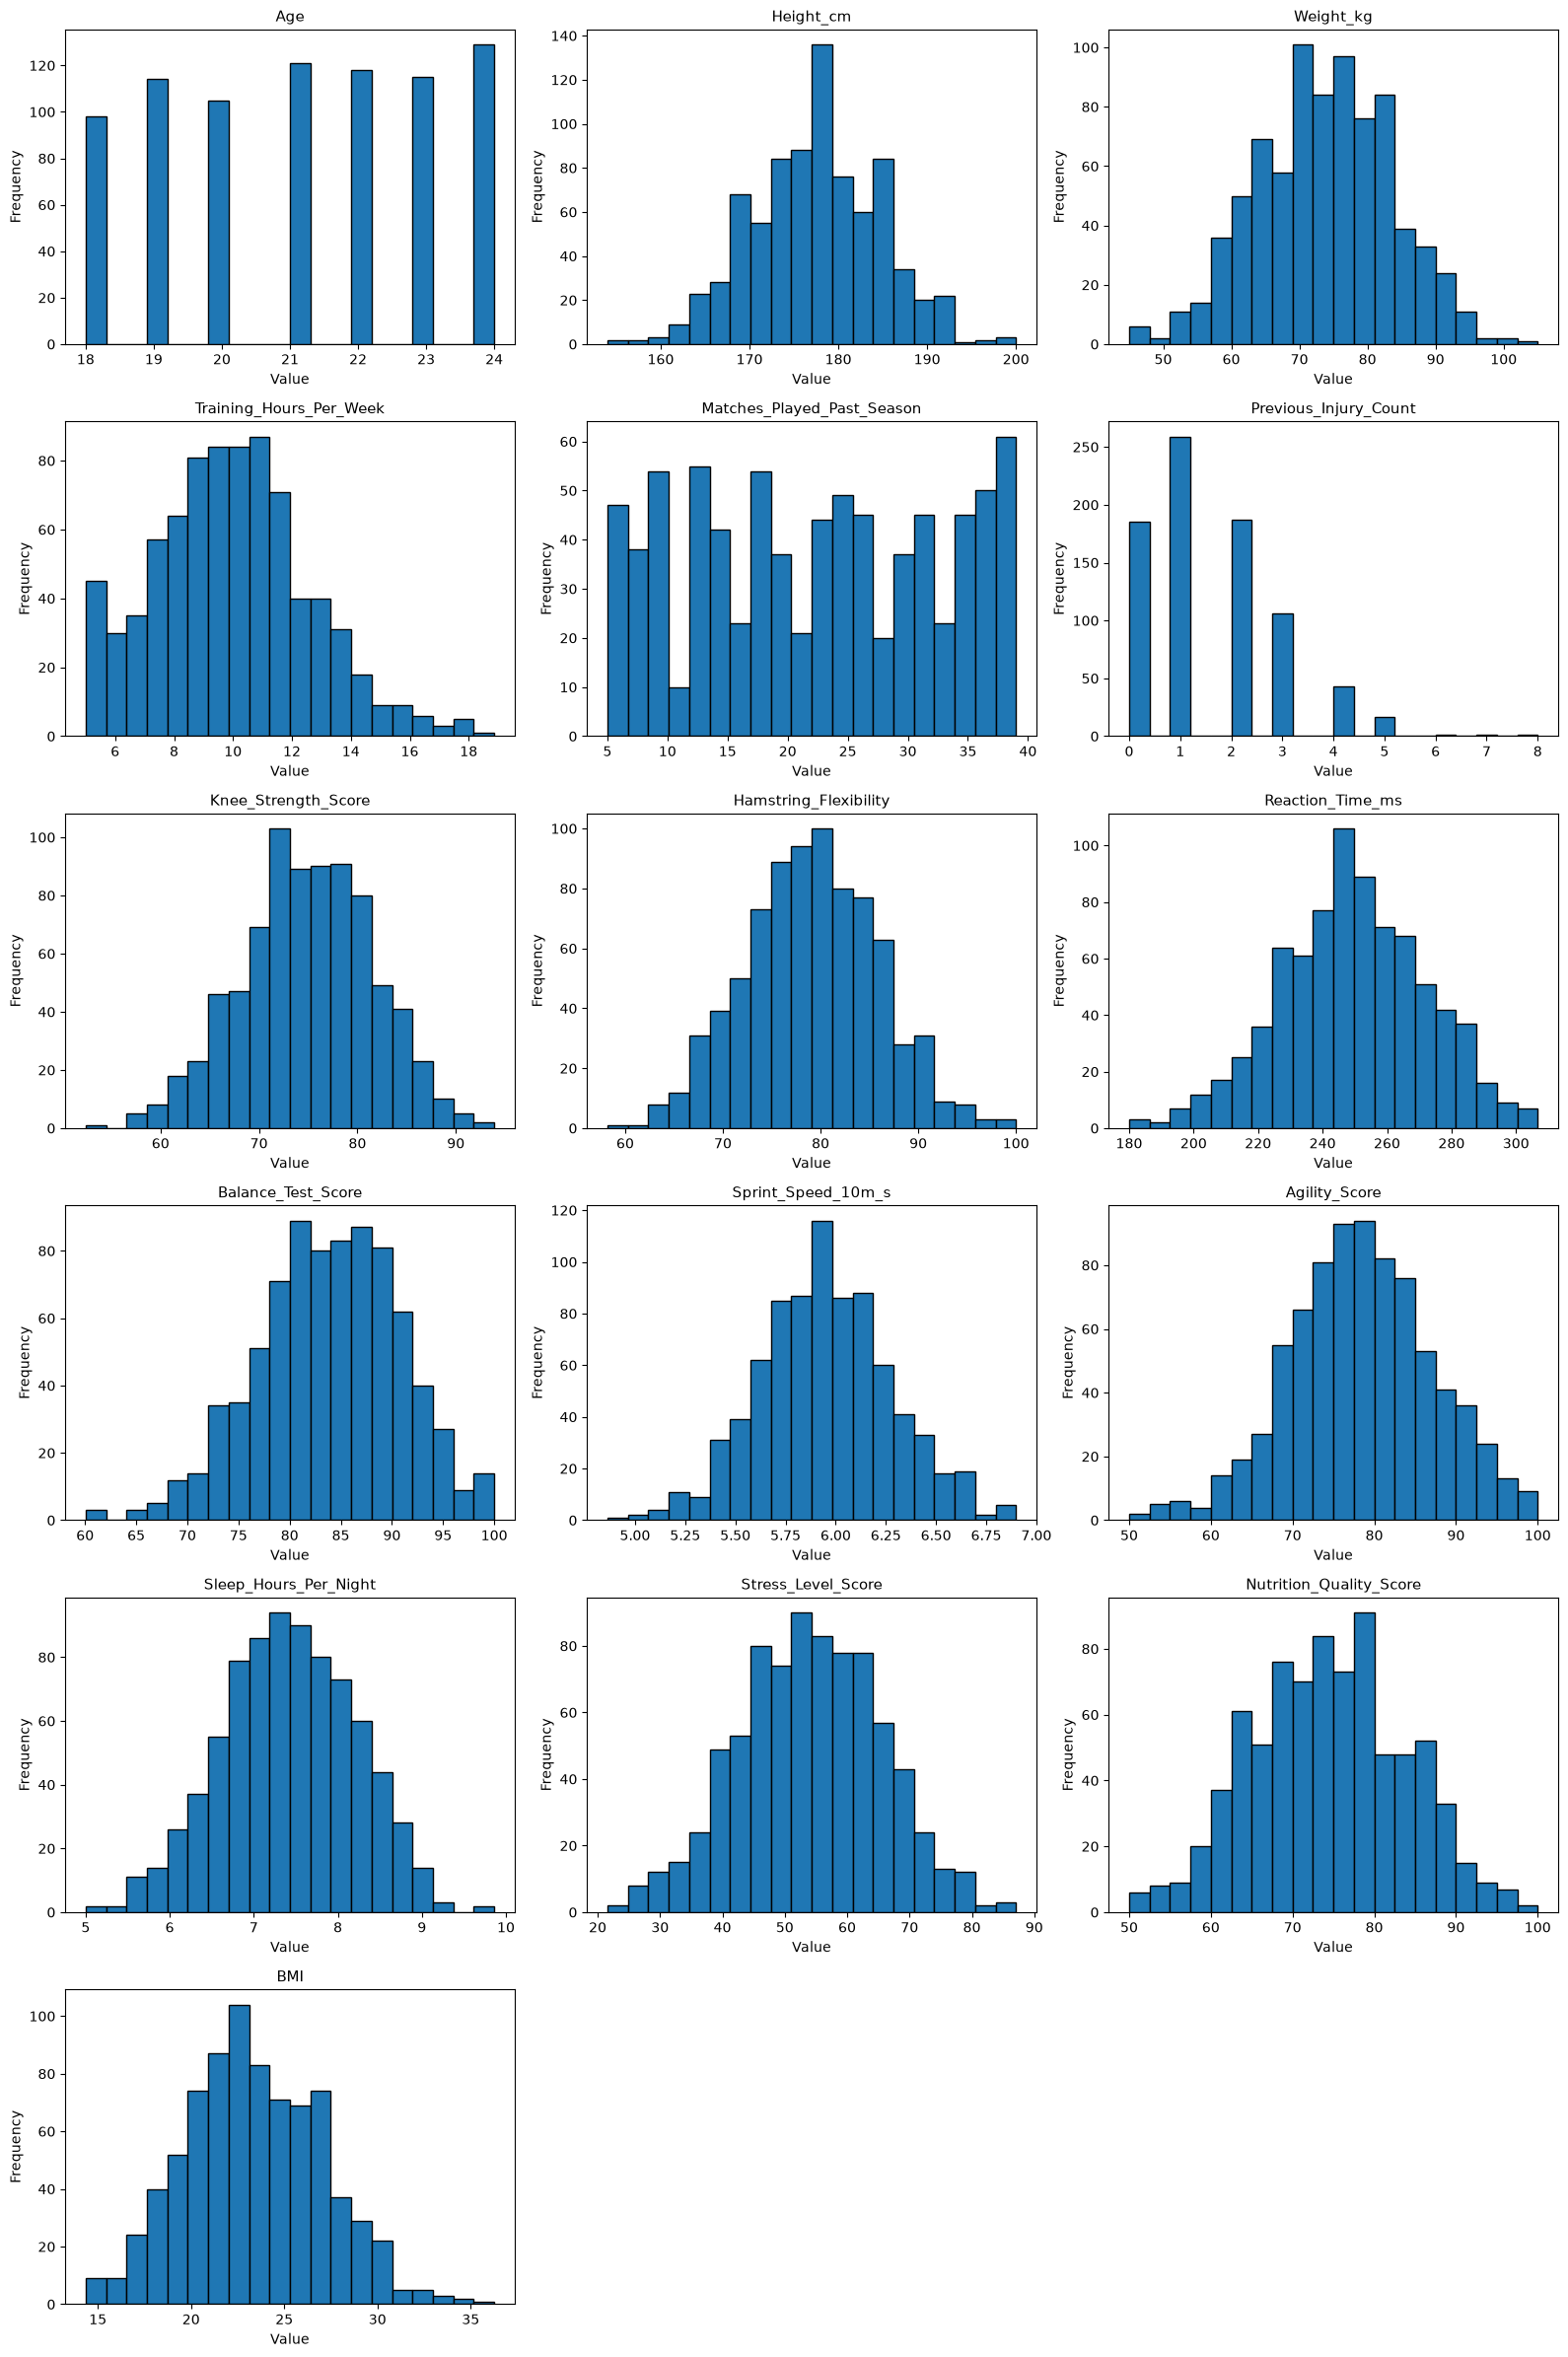

In [23]:
# 選擇數值型自變數
numeric_cols = df.select_dtypes(include="number").columns.tolist()

# 排除二元類別型變數與應變數
numeric_cols = [
    col for col in numeric_cols
    if col not in [
        "Warmup_Routine_Adherence",
        "Injury_Next_Season"
    ]
]

# 畫出所有數值型變數的直方圖
n_cols = 3
n_rows = math.ceil(len(numeric_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(16, 4 * n_rows)
)

axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(
        df[col],
        bins=20,
        edgecolor="black"
    )

    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")

# 移除空白子圖
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [24]:
outlier_summary = []

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (df[col] < lower) | (df[col] > upper)

    outlier_summary.append({
        "Variable": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Outlier Count": int(outliers.sum()),
        "Outlier Percentage": round(outliers.mean() * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)

display(
    outlier_df.sort_values(
        "Outlier Percentage",
        ascending=False
    )
)

,Variable,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
5,Previous_Injury_Count,-0.50,3.50,63,7.88
1,Height_cm,159.50,195.50,11,1.38
3,Training_Hours_Per_Week,3.02,16.65,10,1.25
10,Sprint_Speed_10m_s,5.09,6.80,9,1.12
11,Agility_Score,55.55,101.22,7,0.88
7,Hamstring_Flexibility,60.52,97.79,4,0.50
8,Reaction_Time_ms,187.57,311.63,3,0.38
9,Balance_Test_Score,64.30,103.63,3,0.38
15,BMI,12.93,33.88,3,0.38
12,Sleep_Hours_Per_Night,5.14,9.70,2,0.25


## Data Splitting

In [25]:
from sklearn.model_selection import train_test_split

# 定義目標變數
target = "Injury_Next_Season"

# Stratified Holdout Split：80% Development、20% Testing
dev_df, test_df = train_test_split(
    df,
    test_size=0.20,     # 保留 20% 作為最終測試集
    random_state=42,
    stratify=df[target] # 依照 Y 的類別比例進行分層抽樣
)

# 顯示切分後的資料數量與類別比例
summary = []

for name, subset in [
    ("Development", dev_df),
    ("Testing", test_df)
]:
    summary.append({
        "Dataset": name,
        "Samples": len(subset),
        "Not Injured (0)": (subset[target] == 0).sum(),
        "Injured (1)": (subset[target] == 1).sum()
    })

display(pd.DataFrame(summary))


,Dataset,Samples,Not Injured (0),Injured (1)
0,Development,640,320,320
1,Testing,160,80,80


## EDA & Conditional Independence Analysis

聚焦在：
1. 不同 Y 類別下，各個特徵的分布是否不同
2. 數值型特徵在給定 Y 後，是否仍具有明顯相依性
3. Position 與 Warmup_Routine_Adherence 等類別變數，應如何放入 Naive Bayes
4. 在已知球員是否受傷的情況下，哪些特徵之間仍然存在相依性？這些關係可能對 Naive Bayes 的建模假設造成什麼影響？

### Numerical Feature Correlation by Injury Class

BMI、Weight、Height 有明顯相關性，除此之外沒有明顯線性相關性。

檢測 BMI 的計算公式，確定完全由身高體重取得資訊，因此決定刪除BMI欄位

In [26]:
# 排除目標變數及類別型變數
numeric_features = (
    dev_df
    .drop(columns=["Injury_Next_Season", "Position"])
    .select_dtypes(include="number")
    .columns
)

# 分別計算 Y=0 與 Y=1 的 Pearson 相關係數矩陣
corr_y0 = dev_df.loc[
    dev_df["Injury_Next_Season"] == 0,
    numeric_features
].corr()

corr_y1 = dev_df.loc[
    dev_df["Injury_Next_Season"] == 1,
    numeric_features
].corr()

print("Y = 0：Not Injured")
display(corr_y0.round(2))

print("Y = 1：Injured")
display(corr_y1.round(2))


Y = 0：Not Injured


,Age,Height_cm,Weight_kg,Training_Hours_Per_Week,Matches_Played_Past_Season,Previous_Injury_Count,Knee_Strength_Score,Hamstring_Flexibility,Reaction_Time_ms,Balance_Test_Score,Sprint_Speed_10m_s,Agility_Score,Sleep_Hours_Per_Night,Stress_Level_Score,Nutrition_Quality_Score,Warmup_Routine_Adherence,BMI
Age,1.00,-0.00,0.00,-0.04,0.07,-0.03,-0.09,0.03,0.00,-0.00,-0.06,0.06,-0.05,-0.02,0.03,0.06,0.01
Height_cm,-0.00,1.00,0.03,0.00,-0.06,0.07,-0.08,-0.02,-0.04,-0.04,-0.09,0.11,0.03,0.00,-0.04,-0.03,-0.48
Weight_kg,0.00,0.03,1.00,0.05,-0.00,-0.02,-0.04,-0.03,0.06,0.04,0.01,0.02,0.02,0.08,-0.04,-0.09,0.86
Training_Hours_Per_Week,-0.04,0.00,0.05,1.00,-0.04,0.10,-0.05,0.06,0.04,-0.02,-0.12,-0.06,-0.00,-0.04,-0.04,0.05,0.04
Matches_Played_Past_Season,0.07,-0.06,-0.00,-0.04,1.00,-0.02,0.13,0.02,0.07,0.03,0.08,-0.04,-0.03,0.00,0.01,-0.02,0.03
Previous_Injury_Count,-0.03,0.07,-0.02,0.10,-0.02,1.00,0.06,-0.07,0.05,-0.02,0.03,-0.09,0.18,0.04,0.05,0.03,-0.05
Knee_Strength_Score,-0.09,-0.08,-0.04,-0.05,0.13,0.06,1.00,-0.07,0.12,-0.02,0.03,0.01,0.06,-0.09,0.00,-0.00,0.00
Hamstring_Flexibility,0.03,-0.02,-0.03,0.06,0.02,-0.07,-0.07,1.00,0.07,0.05,0.07,-0.02,-0.07,-0.04,-0.04,-0.03,-0.02
Reaction_Time_ms,0.00,-0.04,0.06,0.04,0.07,0.05,0.12,0.07,1.00,0.02,0.03,-0.09,0.06,-0.02,0.03,0.12,0.06
Balance_Test_Score,-0.00,-0.04,0.04,-0.02,0.03,-0.02,-0.02,0.05,0.02,1.00,-0.02,0.03,0.02,-0.03,0.00,0.01,0.06


Y = 1：Injured


,Age,Height_cm,Weight_kg,Training_Hours_Per_Week,Matches_Played_Past_Season,Previous_Injury_Count,Knee_Strength_Score,Hamstring_Flexibility,Reaction_Time_ms,Balance_Test_Score,Sprint_Speed_10m_s,Agility_Score,Sleep_Hours_Per_Night,Stress_Level_Score,Nutrition_Quality_Score,Warmup_Routine_Adherence,BMI
Age,1.00,-0.04,-0.03,-0.04,0.04,-0.10,0.08,-0.00,-0.00,-0.09,-0.07,-0.04,0.01,-0.04,-0.00,0.02,-0.01
Height_cm,-0.04,1.00,0.02,-0.13,0.01,0.05,-0.07,-0.07,0.08,-0.05,0.06,0.04,-0.08,0.08,0.09,-0.02,-0.51
Weight_kg,-0.03,0.02,1.00,0.04,-0.05,-0.07,-0.04,0.02,0.11,0.12,-0.10,-0.04,-0.03,0.05,0.01,-0.03,0.85
Training_Hours_Per_Week,-0.04,-0.13,0.04,1.00,0.01,-0.06,0.12,0.04,0.00,0.01,-0.03,0.10,-0.04,-0.11,0.02,0.06,0.09
Matches_Played_Past_Season,0.04,0.01,-0.05,0.01,1.00,0.07,-0.03,0.10,-0.08,-0.05,0.05,-0.01,-0.05,0.09,-0.02,0.03,-0.05
Previous_Injury_Count,-0.10,0.05,-0.07,-0.06,0.07,1.00,0.07,-0.01,0.07,-0.12,0.09,0.03,0.01,0.12,0.12,-0.03,-0.08
Knee_Strength_Score,0.08,-0.07,-0.04,0.12,-0.03,0.07,1.00,0.03,-0.04,0.02,0.02,0.02,0.11,-0.02,-0.10,0.06,0.00
Hamstring_Flexibility,-0.00,-0.07,0.02,0.04,0.10,-0.01,0.03,1.00,0.06,-0.07,0.01,0.09,-0.06,0.07,0.01,-0.03,0.04
Reaction_Time_ms,-0.00,0.08,0.11,0.00,-0.08,0.07,-0.04,0.06,1.00,0.02,0.07,-0.06,-0.03,0.04,0.10,0.01,0.06
Balance_Test_Score,-0.09,-0.05,0.12,0.01,-0.05,-0.12,0.02,-0.07,0.02,1.00,-0.02,0.03,-0.01,0.05,-0.06,0.01,0.13


### Chi-square Test of Conditional Independence

在給定受傷類別後，Position 與 Warmup_Routine_Adherence 未呈現顯著的統計相依性，因此目前沒有強烈證據要求將這兩個類別特徵合併處理。

In [27]:

from scipy.stats import chi2_contingency

for y in [0, 1]:
    # 只選取指定受傷類別
    subset = dev_df[dev_df["Injury_Next_Season"] == y]

    # 建立 Position × Warmup 列聯表
    table = pd.crosstab(
        subset["Position"],
        subset["Warmup_Routine_Adherence"]
    )

    # Chi-square Test of Independence
    chi2, p, dof, expected = chi2_contingency(
        table,
        correction=False
    )

    print(f"\nY = {y}")
    display(table)

    print(f"Chi-square: {chi2:.4f}")
    print(f"Degrees of freedom: {dof}")
    print(f"P-value: {p:.4f}")
    print(f"Minimum expected frequency: {expected.min():.2f}")



Y = 0


Warmup_Routine_Adherence,0,1
Position,,
Defender,28,58
Forward,18,53
Goalkeeper,22,57
Midfielder,16,68


Chi-square: 4.1523
Degrees of freedom: 3
P-value: 0.2455
Minimum expected frequency: 18.64

Y = 1


Warmup_Routine_Adherence,0,1
Position,,
Defender,45,31
Forward,41,41
Goalkeeper,43,29
Midfielder,39,51


Chi-square: 6.1165
Degrees of freedom: 3
P-value: 0.1061
Minimum expected frequency: 34.20


## Data Preprocessing

### Mixed Naive Bayes 的特徵分類

In [28]:
# 定義不同類型的特徵
continuous_features = [
    "Height_cm", "Weight_kg",
    "Training_Hours_Per_Week",
    "Knee_Strength_Score", "Hamstring_Flexibility",
    "Reaction_Time_ms", "Balance_Test_Score",
    "Sprint_Speed_10m_s", "Agility_Score",
    "Sleep_Hours_Per_Night", "Stress_Level_Score",
    "Nutrition_Quality_Score"
]

integer_features = [
    "Age", "Matches_Played_Past_Season",
    "Previous_Injury_Count"
]

binary_features = ["Warmup_Routine_Adherence"]
categorical_features = ["Position"]

# 確認特徵數量
all_features = (
    continuous_features + integer_features
    + binary_features + categorical_features
)

print("Number of features:", len(all_features))
print("All features unique:", len(all_features) == len(set(all_features)))

# 分別計算 Y=0 與 Y=1 的偏態係數
skew_by_class = (
    dev_df.groupby("Injury_Next_Season")[
        continuous_features + integer_features
    ].skew().T
)

skew_by_class.columns = ["Y=0", "Y=1"]

display(skew_by_class.round(3))


Number of features: 17
All features unique: True


,Y=0,Y=1
Height_cm,-0.046,0.096
Weight_kg,-0.036,-0.023
Training_Hours_Per_Week,0.275,0.409
Knee_Strength_Score,-0.210,-0.133
Hamstring_Flexibility,0.032,0.162
Reaction_Time_ms,-0.034,-0.300
Balance_Test_Score,-0.097,-0.191
Sprint_Speed_10m_s,0.100,-0.035
Agility_Score,-0.065,-0.113
Sleep_Hours_Per_Night,-0.181,-0.007


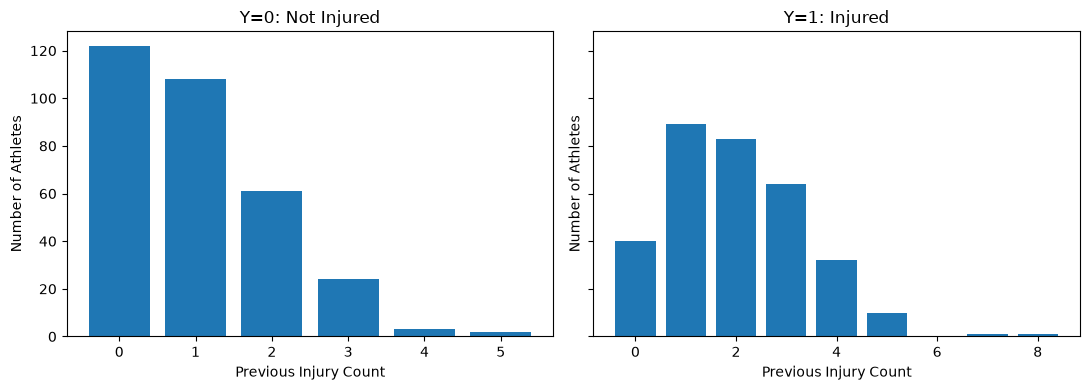

,mean,var,median,max
Injury_Next_Season,,,,
0,1.012,1.059,1.0,5
1,2.000,1.856,2.0,8


In [29]:

import matplotlib.pyplot as plt

feature = "Previous_Injury_Count"

# 分別取得 Y=0、Y=1 的資料
y0 = dev_df.loc[
    dev_df["Injury_Next_Season"] == 0, feature
]

y1 = dev_df.loc[
    dev_df["Injury_Next_Season"] == 1, feature
]

# 比較不同受傷類別的次數分布
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, values, label in zip(
    axes,
    [y0, y1],
    ["Y=0: Not Injured", "Y=1: Injured"]
):
    counts = values.value_counts().sort_index()
    ax.bar(counts.index, counts.values)
    ax.set_title(label)
    ax.set_xlabel("Previous Injury Count")
    ax.set_ylabel("Number of Athletes")

plt.tight_layout()
plt.show()

# 檢查各組的平均數、變異數
summary = dev_df.groupby("Injury_Next_Season")[feature].agg(
    ["mean", "var", "median", "max"]
)

display(summary.round(3))


### Final Feature Selection

In [30]:
# 排除 BMI，其餘特徵保留
selected_features = [
    col for col in df.columns
    if col not in ["BMI", "Injury_Next_Season"]
]

# 建立 Development / Testing 的模型輸入
X_dev = dev_df[selected_features].copy()
y_dev = dev_df["Injury_Next_Season"].copy()

X_test = test_df[selected_features].copy()
y_test = test_df["Injury_Next_Season"].copy()

print("Number of selected features:", len(selected_features))
print("Development X shape:", X_dev.shape)
print("Testing X shape:", X_test.shape)

display(X_dev.head())


Number of selected features: 17
Development X shape: (640, 17)
Testing X shape: (160, 17)


,Age,Height_cm,Weight_kg,Position,Training_Hours_Per_Week,Matches_Played_Past_Season,Previous_Injury_Count,Knee_Strength_Score,Hamstring_Flexibility,Reaction_Time_ms,Balance_Test_Score,Sprint_Speed_10m_s,Agility_Score,Sleep_Hours_Per_Night,Stress_Level_Score,Nutrition_Quality_Score,Warmup_Routine_Adherence
642,23,182,63,Defender,10.411016,16,1,85.308366,91.483525,262.676948,84.796887,5.910784,77.102560,7.271065,48.098171,71.019023,0
310,24,189,75,Goalkeeper,6.810211,32,2,71.592754,68.137815,252.851247,75.735189,5.447982,92.840673,5.706359,63.545761,64.602468,1
583,21,184,77,Defender,18.866608,31,2,63.900676,80.644099,240.403638,85.711525,5.939425,76.313001,7.100870,63.444397,65.901037,0
586,20,187,65,Defender,11.597100,34,1,89.304476,82.642018,255.121148,96.905572,5.732742,87.424301,7.073731,41.619807,89.241249,0
626,19,175,86,Defender,13.835766,18,1,81.301006,84.054015,180.000000,88.984960,6.316222,89.997490,7.635763,29.786196,78.327423,1


### Define Preprocessing for Both Models

In [31]:

from sklearn.compose import ColumnTransformer       # 允許我們對不同欄位使用不同的前處理方法
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Mixed Naive Bayes：Position 保留為單一類別特徵
nb_preprocessor = ColumnTransformer(
    transformers=[
        ("position", OrdinalEncoder(        # 將 Position 的四種類別轉換為整數代碼，非數值
            handle_unknown="use_encoded_value",
            unknown_value=-1                # 用來處理 Validation Fold 中出現、但 Training Fold 沒看過的類別
        ), ["Position"])
    ],
    remainder="passthrough"
)

# Gini Decision Tree：Position 使用 One-Hot Encoding
tree_preprocessor = ColumnTransformer(
    transformers=[
        ("position", OneHotEncoder(         # 將 Position 的四種類別轉換為 One-Hot Encoding
            handle_unknown="ignore",
            sparse_output=False
        ), ["Position"])
    ],
    remainder="passthrough"
)

print("Naive Bayes preprocessor created.")
print("Decision Tree preprocessor created.")


Naive Bayes preprocessor created.
Decision Tree preprocessor created.


# Mixed Naive Bayes Modeling

只計算一次 Prior，然後分別計算 Gaussian、Categorical、Bernoulli 的 Likelihood，最後將它們組合。

In [32]:
# 定義分類器

class MixedNaiveBayes(ClassifierMixin, BaseEstimator):

    # 初始化方法
    def __init__(self, numeric_indices, position_index,
                 warmup_index, alpha=1.0):
        self.numeric_indices = numeric_indices
        self.position_index = position_index
        self.warmup_index = warmup_index
        self.alpha = alpha

    # 擬合模型
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        if self.alpha <= 0:
            raise ValueError("alpha must be greater than 0.")

        # 1. Class prior probabilities
        self.classes_, counts = np.unique(
            y, return_counts=True
        )
        self.class_counts_ = counts
        self.n_samples_ = len(y)

        self.log_priors_ = np.log(counts / len(y))

        # 2. Initialize parameters
        self.means_ = []
        self.stds_ = []
        self.position_probs_ = []
        self.warmup_probs_ = []

        # Position category count
        positions = X[:, self.position_index].astype(int)

        if np.any(positions < 0):
            raise ValueError(
                "Training data contains unknown Position codes."
            )

        self.n_positions_ = positions.max() + 1

        # 3. Estimate parameters for each class
        for cls in self.classes_:

            X_cls = X[y == cls]
            n = len(X_cls)

            # Gaussian likelihood
            numeric = X_cls[:, self.numeric_indices]

            mean = numeric.mean(axis=0)
            variance = np.maximum(
                numeric.var(axis=0), 1e-9
            )

            self.means_.append(mean)
            self.stds_.append(np.sqrt(variance))

            # Categorical likelihood: Position
            pos_counts = np.bincount(
                X_cls[:, self.position_index].astype(int),
                minlength=self.n_positions_
            )

            # Reserve one category for unknown values
            denominator = (
                n + self.alpha * (self.n_positions_ + 1)
            )

            pos_probs = (
                (pos_counts + self.alpha) / denominator
            )

            self.position_probs_.append(pos_probs)

            # Bernoulli likelihood: Warmup
            warmup = X_cls[:, self.warmup_index]

            if not np.all(np.isin(warmup, [0, 1])):
                raise ValueError(
                    "Warmup values must be 0 or 1."
                )

            p_warmup = (
                (warmup.sum() + self.alpha)
                / (n + 2 * self.alpha)
            )

            self.warmup_probs_.append(p_warmup)

        self.means_ = np.asarray(self.means_)
        self.stds_ = np.asarray(self.stds_)

        self.n_features_in_ = X.shape[1]

        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(1, -1)

        if X.shape[1] != self.n_features_in_:
            raise ValueError("Incorrect number of features.")

        log_scores = []

        # 4. Calculate posterior scores
        for j, cls in enumerate(self.classes_):

            # Log prior
            score = np.full(
                len(X), self.log_priors_[j]
            )

            # Gaussian log likelihood
            numeric = X[:, self.numeric_indices]

            log_gaussian = norm.logpdf(
                numeric,
                loc=self.means_[j],
                scale=self.stds_[j]
            )

            score += log_gaussian.sum(axis=1)

            # Categorical log likelihood: Position
            pos = X[:, self.position_index].astype(int)

            denominator = (
                self.class_counts_[j]
                + self.alpha * (self.n_positions_ + 1)
            )

            # Probability for unknown category
            pos_prob = np.full(
                len(X),
                self.alpha / denominator
            )

            known = (
                (pos >= 0)
                & (pos < self.n_positions_)
            )

            pos_prob[known] = (
                self.position_probs_[j][pos[known]]
            )

            score += np.log(pos_prob)

            # Bernoulli log likelihood: Warmup
            warmup = X[:, self.warmup_index]
            p = self.warmup_probs_[j]

            score += (
                warmup * np.log(p)
                + (1 - warmup) * np.log(1 - p)
            )

            log_scores.append(score)

        # 5. Normalize posterior probabilities
        log_scores = np.column_stack(log_scores)

        probabilities = np.exp(
            log_scores
            - logsumexp(
                log_scores, axis=1, keepdims=True
            )
        )

        return probabilities

    def predict(self, X):
        # 6. Predict the class with highest probability
        probabilities = self.predict_proba(X)

        return self.classes_[
            np.argmax(probabilities, axis=1)
        ]


print("MixedNaiveBayes class defined successfully.")



MixedNaiveBayes class defined successfully.


In [33]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# 1. 確認 Preprocessor 輸出的欄位順序
encoded_features = (
    ["Position"] +
    [col for col in selected_features if col != "Position"]
)

position_index = encoded_features.index("Position")
warmup_index = encoded_features.index("Warmup_Routine_Adherence")

numeric_indices = [
    i for i, col in enumerate(encoded_features)
    if col not in ["Position", "Warmup_Routine_Adherence"]
]

print("Position index:", position_index)
print("Warmup index:", warmup_index)
print("Number of numeric features:", len(numeric_indices))

# 2. 建立完整 Mixed Naive Bayes Pipeline
nb_pipeline = Pipeline([
    ("preprocessor", clone(nb_preprocessor)),
    ("classifier", MixedNaiveBayes(
        numeric_indices=numeric_indices,
        position_index=position_index,
        warmup_index=warmup_index,
        alpha=1.0
    ))
])

# 3. 使用 Development Data 的小樣本進行功能測試
sample_df = dev_df.groupby(
    "Injury_Next_Season",
    group_keys=False
).sample(n=50, random_state=42)

X_sample = sample_df[selected_features]
y_sample = sample_df["Injury_Next_Season"]

test_pipeline = clone(nb_pipeline)
test_pipeline.fit(X_sample, y_sample)

# 4. 檢查預測類別與機率
predictions = test_pipeline.predict(X_sample.head())
probabilities = test_pipeline.predict_proba(X_sample.head())

print("\nPredictions:", predictions)
print("\nPredicted probabilities:")
print(np.round(probabilities, 4))

print("\nProbability sums:")
print(probabilities.sum(axis=1))


Position index: 0
Warmup index: 16
Number of numeric features: 15

Predictions: [0 0 0 1 0]

Predicted probabilities:
[[0.6674 0.3326]
 [1.     0.    ]
 [1.     0.    ]
 [0.0301 0.9699]
 [0.9849 0.0151]]

Probability sums:
[1. 1. 1. 1. 1.]


# Gini Decision Tree Modeling

使用 DecisionTreeClassifier。

criterion="gini"。

透過 tree_preprocessor 對 Position 進行 One-Hot Encoding。

後續使用 Cost-Complexity Pruning 控制模型複雜度。

與 Mixed Naive Bayes 使用相同的 Stratified 5-Fold。

## Model Setup

In [34]:
# 建立 Gini Decision Tree Pipeline
tree_pipeline = Pipeline([
    ("preprocessor", clone(tree_preprocessor)),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        random_state=42,
        ccp_alpha=0.0
    ))
])

print("Gini Decision Tree Pipeline created.")

# 確認模型參數
print("\nDecision Tree Parameters:")
print(tree_pipeline.named_steps["classifier"].get_params())


Gini Decision Tree Pipeline created.

Decision Tree Parameters:
{'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}


### Cost-Complexity Pruning with Stratified 5-Fold CV

In [35]:
# 1. 建立共同的 Stratified 5-Fold
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 2. 設定事先選定的剪枝參數候選值
param_grid = {
    "classifier__ccp_alpha": [
        0.0, 0.001, 0.002, 0.005,
        0.01, 0.02, 0.04
    ]
}

# 3. 使用 5-Fold 選擇最佳剪枝參數
tree_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    refit=True,
    n_jobs=-1
)

# 4. 在 Development Data 上執行
tree_search.fit(X_dev, y_dev)

print("Best ccp_alpha:",
      tree_search.best_params_["classifier__ccp_alpha"])

print("Best CV F1-score:",
      round(tree_search.best_score_, 4))


Best ccp_alpha: 0.0
Best CV F1-score: 0.8193


In [36]:
# 整理各 ccp_alpha 的五折交叉驗證結果
pruning_results = pd.DataFrame({
    "ccp_alpha": tree_search.cv_results_[
        "param_classifier__ccp_alpha"
    ],
    "Mean_CV_F1": tree_search.cv_results_[
        "mean_test_score"
    ],
    "Std_CV_F1": tree_search.cv_results_[
        "std_test_score"
    ]
})

display(pruning_results.round(4))

# 取得最佳決策樹
best_tree = tree_search.best_estimator_

tree_model = best_tree.named_steps["classifier"]

print("Best Tree Depth:", tree_model.get_depth())
print("Best Tree Leaves:", tree_model.get_n_leaves())
print("Best Tree Nodes:", tree_model.tree_.node_count)


,ccp_alpha,Mean_CV_F1,Std_CV_F1
0,0.000,0.8193,0.0480
1,0.001,0.8193,0.0480
2,0.002,0.8159,0.0416
3,0.005,0.8034,0.0247
4,0.010,0.8058,0.0247
5,0.020,0.7834,0.0162
6,0.040,0.7619,0.0151


Best Tree Depth: 12
Best Tree Leaves: 55
Best Tree Nodes: 109


# Model Evaluation and Comparison

## Stratified 5-Fold Cross-Validation

In [39]:
# 評估指標
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

# 使用已確定的兩個模型
models = {
    "Mixed Naive Bayes": nb_pipeline,
    "Gini Decision Tree": tree_search.best_estimator_
}

cv_results = {}

# 使用相同的 Stratified 5-Fold
for name, model in models.items():

    scores = cross_validate(
        estimator=clone(model),
        X=X_dev,
        y=y_dev,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results[name] = {               # 保留了每一折的原始評估結果
        metric: scores[f"test_{metric}"]
        for metric in scoring
    }

# 整理平均分數與標準差
summary_rows = []

for name, results in cv_results.items():
    row = {"Model": name}

    for metric, values in results.items():
        row[f"{metric}_Mean"] = values.mean()
        row[f"{metric}_Std"] = values.std()

    summary_rows.append(row)

cv_summary = pd.DataFrame(summary_rows)

display(cv_summary.round(4))


,Model,Accuracy_Mean,Accuracy_Std,Precision_Mean,Precision_Std,Recall_Mean,Recall_Std,F1_Mean,F1_Std,ROC_AUC_Mean,ROC_AUC_Std
0,Mixed Naive Bayes,0.9391,0.0229,0.9327,0.0262,0.9469,0.0290,0.9395,0.0227,0.9884,0.0068
1,Gini Decision Tree,0.8234,0.0432,0.8357,0.0417,0.8062,0.0696,0.8193,0.0480,0.8234,0.0432


In [40]:
from scipy.stats import t

# 使用原本 Cell 43 已經計算完成的 cv_results
confidence_level = 0.95

ci_rows = []

for model_name, metric_results in cv_results.items():

    for metric_name, fold_scores in metric_results.items():

        scores = np.asarray(fold_scores, dtype=float)

        n = len(scores)
        mean_score = np.mean(scores)

        # 使用樣本標準差（ddof=1）
        std_score = np.std(scores, ddof=1)

        # 標準誤
        standard_error = std_score / np.sqrt(n)

        # t 分布臨界值
        t_critical = t.ppf(
            (1 + confidence_level) / 2,
            df=n - 1
        )

        margin = t_critical * standard_error

        ci_rows.append({
            "Model": model_name,
            "Metric": metric_name,
            "Mean": mean_score,
            "Std": std_score,
            "CI_Lower": mean_score - margin,
            "CI_Upper": mean_score + margin
        })

ci_summary = pd.DataFrame(ci_rows)

display(ci_summary.round(4))


,Model,Metric,Mean,Std,CI_Lower,CI_Upper
0,Mixed Naive Bayes,Accuracy,0.9391,0.0256,0.9073,0.9708
1,Mixed Naive Bayes,Precision,0.9327,0.0293,0.8964,0.9691
2,Mixed Naive Bayes,Recall,0.9469,0.0324,0.9066,0.9871
3,Mixed Naive Bayes,F1,0.9395,0.0254,0.9080,0.9710
4,Mixed Naive Bayes,ROC_AUC,0.9884,0.0077,0.9789,0.9979
5,Gini Decision Tree,Accuracy,0.8234,0.0483,0.7634,0.8835
6,Gini Decision Tree,Precision,0.8357,0.0466,0.7778,0.8936
7,Gini Decision Tree,Recall,0.8062,0.0778,0.7096,0.9029
8,Gini Decision Tree,F1,0.8193,0.0537,0.7526,0.8860
9,Gini Decision Tree,ROC_AUC,0.8234,0.0483,0.7634,0.8835


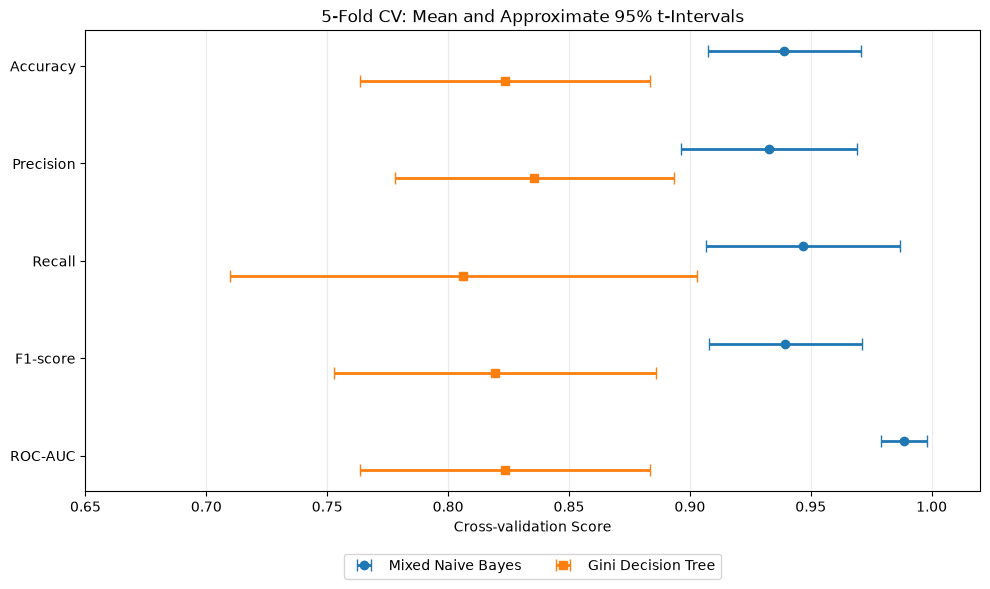

In [ ]:
# 進行95%區間估計
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
models = ["Mixed Naive Bayes", "Gini Decision Tree"]

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(metrics))

for offset, model, marker in [
    (-0.15, models[0], "o"),
    (0.15, models[1], "s")
]:
    data = (
        ci_summary[ci_summary["Model"] == model]
        .set_index("Metric")
        .loc[metrics]
    )

    mean = data["Mean"].to_numpy()
    lower = data["CI_Lower"].to_numpy()
    upper = data["CI_Upper"].to_numpy()

    ax.errorbar(
        mean,
        y + offset,
        xerr=[mean - lower, upper - mean],
        fmt=marker,
        capsize=4,
        linewidth=2,
        markersize=6,
        label=model
    )

ax.set_yticks(y)
ax.set_yticklabels([
    "Accuracy", "Precision", "Recall",
    "F1-score", "ROC-AUC"
])

ax.invert_yaxis()
ax.set_xlim(0.65, 1.02)
ax.set_xlabel("Cross-validation Score")
ax.set_title(
    "5-Fold CV: Mean and Approximate 95% t-Intervals"
)
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="upper center",
          bbox_to_anchor=(0.5, -0.12),
          ncol=2)

plt.tight_layout()
plt.savefig("CV_Confidence_Intervals.png",
            dpi=300, bbox_inches="tight")
plt.show()


# Final Testing

In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. 使用全部 Development Data 訓練 Mixed NB
final_nb = clone(nb_pipeline)
final_nb.fit(X_dev, y_dev)

# 2. 使用已經完成 Refit 的最佳 Gini Tree
final_tree = tree_search.best_estimator_

# 3. 最終測試模型
final_models = {
    "Mixed Naive Bayes": final_nb,
    "Gini Decision Tree": final_tree
}

test_results = []

for name, model in final_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC_AUC": roc_auc_score(y_test, y_prob)
    })

test_summary = pd.DataFrame(test_results)

display(test_summary.round(4))


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Mixed Naive Bayes,0.9875,1.0000,0.9750,0.9873,0.9988
1,Gini Decision Tree,0.7500,0.7703,0.7125,0.7403,0.7500


### Confusion Matrix

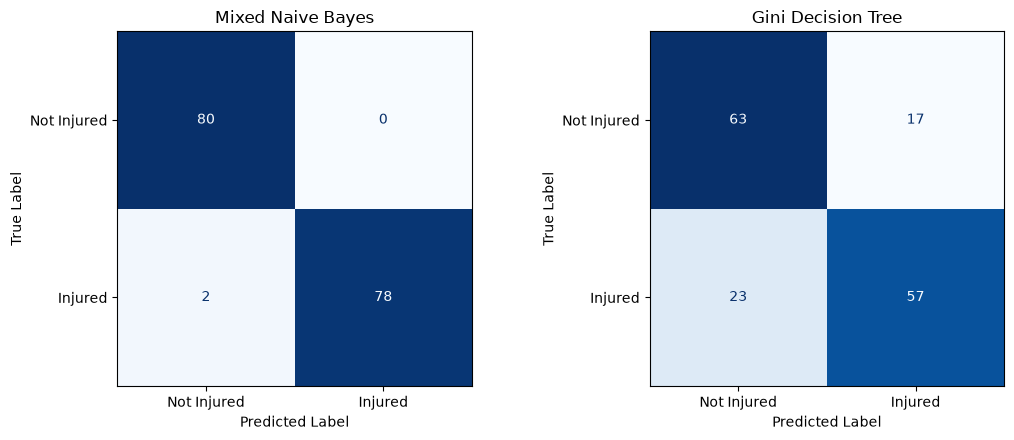

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (name, model) in zip(axes, final_models.items()):

    y_pred = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["Not Injured", "Injured"],
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()


### ROC Curve Comparison

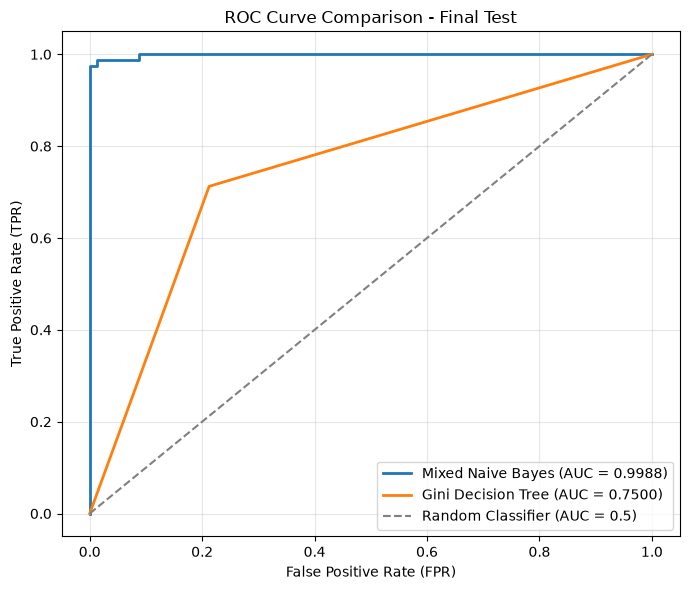

In [35]:
plt.figure(figsize=(7, 6))

# 分別繪製兩個模型的 ROC Curve
for name, model in final_models.items():

    # 取得預測為受傷 (Y=1) 的機率
    y_prob = model.predict_proba(X_test)[:, 1]

    # 計算 ROC Curve
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    # 計算 ROC-AUC
    auc = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.4f})"
    )

# 隨機分類器參考線
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier (AUC = 0.5)"
)

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve Comparison - Final Test")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Final Model Training Using the Full Dataset

After model selection and holdout evaluation, the selected
Mixed Naive Bayes model is refitted using all 800 observations.

The original testing results remain unchanged.


In [42]:
# 1. 建立完整資料集（800 筆）
# 沿用原本選出的 17 個特徵，不包含 BMI
X_full = df[selected_features].copy()
y_full = df["Injury_Next_Season"].copy()

print("Full Dataset Shape:", X_full.shape)
print("Target Shape:", y_full.shape)

print("\nClass Distribution:")
print(y_full.value_counts().sort_index())

print("\nNumber of Selected Features:", len(selected_features))

# 2. 確認資料完整性
assert len(X_full) == 800, "Dataset size is not 800."
assert X_full.shape[1] == 17, "Expected 17 features."
assert not X_full.isnull().any().any(), "Missing feature values."
assert not y_full.isnull().any(), "Missing target values."
assert "BMI" not in X_full.columns, "BMI should be excluded."

# 3. 複製原本的 Mixed Naive Bayes Pipeline
# 不覆蓋原本 final_nb，也不修改原本測試結果
final_nb_full = clone(nb_pipeline)

# 4. 使用全部 800 筆資料重新訓練
final_nb_full.fit(X_full, y_full)

print("\nFinal Model Training Completed!")
print("Model: Mixed Naive Bayes")
print("Training Samples:", len(X_full))
print("Number of Features:", X_full.shape[1])

# 5. 確認模型已經完成訓練
final_classifier = final_nb_full.named_steps["classifier"]

print("\nModel Classes:", final_classifier.classes_)
print("Class Counts:", final_classifier.class_counts_)
print("Model Training Samples:", final_classifier.n_samples_)

# 6. 簡單檢查模型能否輸出預測結果
sample_X = X_full.head(5)

sample_pred = final_nb_full.predict(sample_X)
sample_prob = final_nb_full.predict_proba(sample_X)

print("\nSample Predictions:")
print(sample_pred)

print("\nSample Probabilities:")
print(np.round(sample_prob, 4))


Full Dataset Shape: (800, 17)
Target Shape: (800,)

Class Distribution:
Injury_Next_Season
0    400
1    400
Name: count, dtype: int64

Number of Selected Features: 17

Final Model Training Completed!
Model: Mixed Naive Bayes
Training Samples: 800
Number of Features: 17

Model Classes: [0 1]
Class Counts: [400 400]
Model Training Samples: 800

Sample Predictions:
[0 0 1 0 1]

Sample Probabilities:
[[9.773e-01 2.270e-02]
 [9.975e-01 2.500e-03]
 [2.070e-02 9.793e-01]
 [9.996e-01 4.000e-04]
 [8.280e-02 9.172e-01]]


In [45]:
# 輸出模型結果

# 取得已經使用 800 筆資料訓練完成的模型
nb_model = final_nb_full.named_steps["classifier"]
preprocessor = final_nb_full.named_steps["preprocessor"]

# 1. 類別先驗機率
prior_table = pd.DataFrame({
    "Class": nb_model.classes_,
    "Count": nb_model.class_counts_,
    "Prior": np.exp(nb_model.log_priors_)
})

print("Class Prior Probabilities")
display(prior_table.round(4))

# 2. Gaussian 參數表
# 對應原本 Notebook 的 encoded_features 欄位順序
numeric_names = [
    encoded_features[i]
    for i in nb_model.numeric_indices
]

gaussian_table = pd.DataFrame({
    "Feature": numeric_names,
    "Mean_Y0": nb_model.means_[0],
    "Std_Y0": nb_model.stds_[0],
    "Mean_Y1": nb_model.means_[1],
    "Std_Y1": nb_model.stds_[1]
})

print("\nGaussian Parameters")
display(gaussian_table.round(4))

# 3. Position 的 Categorical 條件機率
position_categories = (
    preprocessor
    .named_transformers_["position"]
    .categories_[0]
)

position_table = pd.DataFrame({
    "Position": position_categories,
    "P_Position_given_Y0": nb_model.position_probs_[0],
    "P_Position_given_Y1": nb_model.position_probs_[1]
})

print("\nPosition Conditional Probabilities")
display(position_table.round(4))

# 4. Warmup 的 Bernoulli 條件機率
warmup_table = pd.DataFrame({
    "Class": nb_model.classes_,
    "P_Warmup_1": nb_model.warmup_probs_,
    "P_Warmup_0": 1 - np.asarray(nb_model.warmup_probs_)
})

print("\nWarmup Conditional Probabilities")
display(warmup_table.round(4))


Class Prior Probabilities


,Class,Count,Prior
0,0,400,0.5
1,1,400,0.5



Gaussian Parameters


,Feature,Mean_Y0,Std_Y0,Mean_Y1,Std_Y1
0,Age,21.0925,2.0147,21.1775,1.9637
1,Height_cm,177.8000,7.0449,177.0150,7.2215
2,Weight_kg,73.0250,10.0339,73.4450,9.8065
3,Training_Hours_Per_Week,9.8630,2.5727,10.0393,2.6414
4,Matches_Played_Past_Season,22.7850,10.6327,21.8800,9.9461
5,Previous_Injury_Count,1.0425,0.9928,2.0300,1.3653
6,Knee_Strength_Score,77.9644,5.8805,71.9021,5.9985
7,Hamstring_Flexibility,82.2064,5.9889,76.1018,6.1143
8,Reaction_Time_ms,238.8199,19.7787,260.0266,19.9522
9,Balance_Test_Score,87.2601,5.7130,80.4046,6.3117



Position Conditional Probabilities


,Position,P_Position_given_Y0,P_Position_given_Y1
0,Defender,0.2617,0.2469
1,Forward,0.2247,0.2667
2,Goalkeeper,0.2469,0.2173
3,Midfielder,0.2642,0.2667



Warmup Conditional Probabilities


,Class,P_Warmup_1,P_Warmup_0
0,0,0.7264,0.2736
1,1,0.4677,0.5323


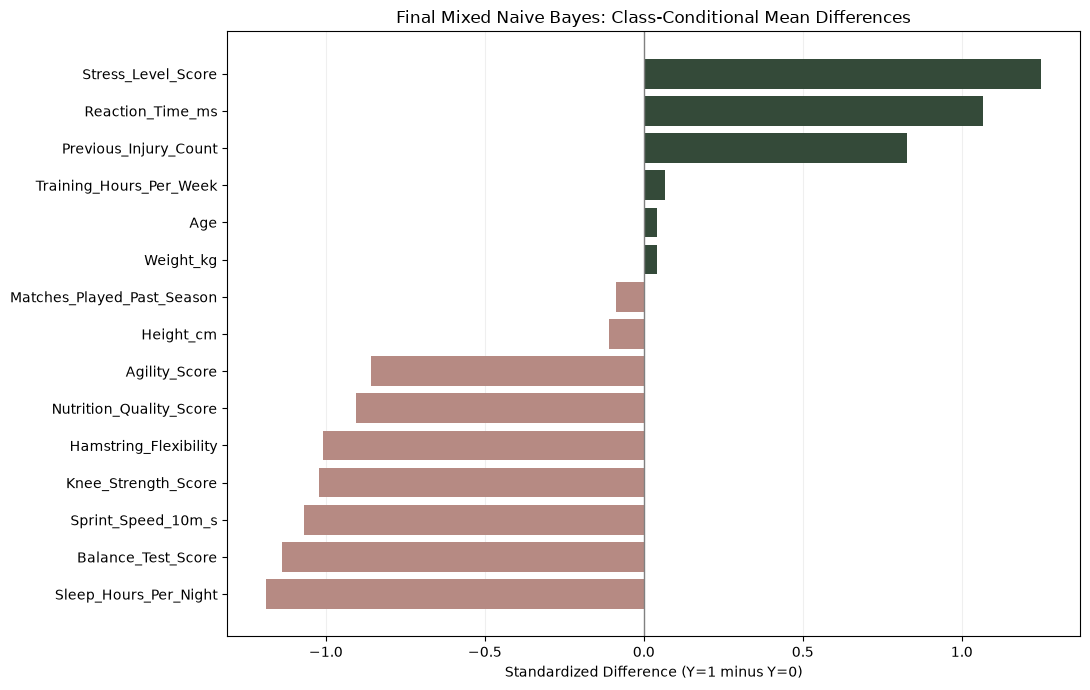

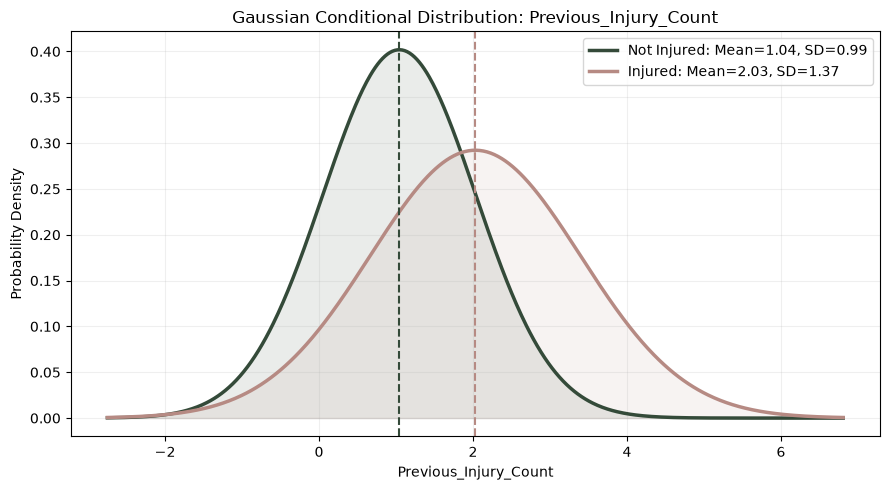

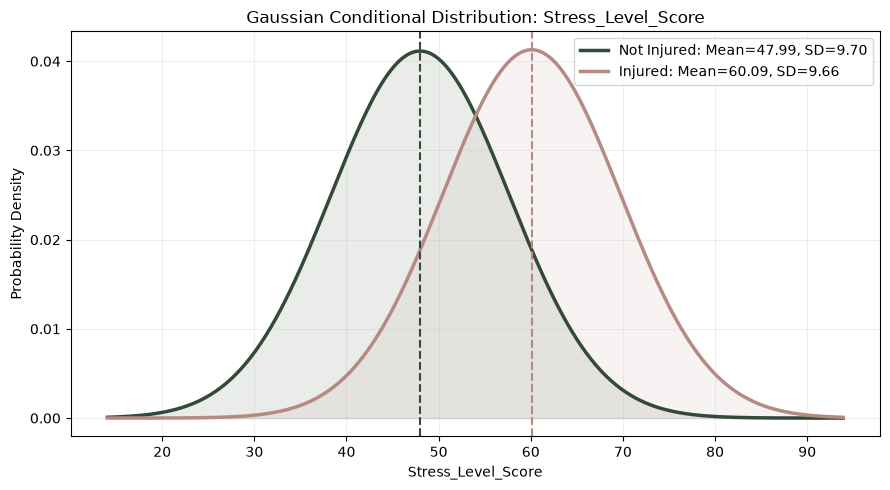

In [46]:

# 使用原本的最終模型參數表
plot_df = gaussian_table.copy()

# 依照你目前簡報的配色
COLOR_Y0 = "#344A39"  # 未受傷：深綠
COLOR_Y1 = "#B68A83"  # 受傷：灰粉

# ==================================================
# Chart A: Standardized Mean Differences
# ==================================================

plot_df["Std_Difference"] = (
    (plot_df["Mean_Y1"] - plot_df["Mean_Y0"])
    / np.sqrt(
        (plot_df["Std_Y0"]**2 + plot_df["Std_Y1"]**2) / 2
    )
)

plot_df = plot_df.sort_values("Std_Difference")

fig, ax = plt.subplots(figsize=(11, 7))

colors = [
    COLOR_Y1 if x < 0 else COLOR_Y0
    for x in plot_df["Std_Difference"]
]

ax.barh(
    plot_df["Feature"],
    plot_df["Std_Difference"],
    color=colors
)

ax.axvline(0, color="gray", linewidth=1)

ax.set_title(
    "Final Mixed Naive Bayes: "
    "Class-Conditional Mean Differences"
)
ax.set_xlabel(
    "Standardized Difference (Y=1 minus Y=0)"
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    "Final_Model_Standardized_Differences.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ==================================================
# Chart B/C: Gaussian Conditional Distributions
# ==================================================

def plot_gaussian_feature(feature_name):

    row = gaussian_table.set_index("Feature").loc[
        feature_name
    ]

    mu0 = row["Mean_Y0"]
    mu1 = row["Mean_Y1"]
    sd0 = row["Std_Y0"]
    sd1 = row["Std_Y1"]

    x_min = min(mu0 - 3.5*sd0, mu1 - 3.5*sd1)
    x_max = max(mu0 + 3.5*sd0, mu1 + 3.5*sd1)

    x = np.linspace(x_min, x_max, 600)

    density0 = norm.pdf(x, loc=mu0, scale=sd0)
    density1 = norm.pdf(x, loc=mu1, scale=sd1)

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.plot(
        x, density0,
        color=COLOR_Y0,
        linewidth=2.5,
        label=f"Not Injured: Mean={mu0:.2f}, SD={sd0:.2f}"
    )

    ax.plot(
        x, density1,
        color=COLOR_Y1,
        linewidth=2.5,
        label=f"Injured: Mean={mu1:.2f}, SD={sd1:.2f}"
    )

    ax.fill_between(x, density0, color=COLOR_Y0, alpha=0.10)
    ax.fill_between(x, density1, color=COLOR_Y1, alpha=0.10)

    ax.axvline(mu0, color=COLOR_Y0, linestyle="--")
    ax.axvline(mu1, color=COLOR_Y1, linestyle="--")

    ax.set_title(
        f"Gaussian Conditional Distribution: {feature_name}"
    )
    ax.set_xlabel(feature_name)
    ax.set_ylabel("Probability Density")

    ax.legend()
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.savefig(
        f"Gaussian_{feature_name}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()


# 繪製兩個代表性特徵
plot_gaussian_feature("Previous_Injury_Count")
plot_gaussian_feature("Stress_Level_Score")
